# Practical No-04

## Title: Image Generation using Deep Convolutional GAN (DCGAN)

**Name:** Nagawade Chirag Somnath

**PRN:** 202502110009

**Subject:** Generative AI

---

### Aim
To implement a Generative Adversarial Network (GAN) using Python and TensorFlow/Keras to generate synthetic flower images from the Flowers superclass of the CIFAR-100 dataset.

### Objectives
1. To understand the concept and working principle of Generative Adversarial Networks.
2. To load and preprocess flower images from the CIFAR-100 dataset.
3. To implement a generator and a discriminator using convolutional neural network layers.
4. To train the GAN using adversarial learning with binary cross-entropy loss and the Adam optimizer.
5. To generate and visualize synthetic flower images and evaluate the generator's output.

### Dataset Used
The CIFAR-100 dataset is used, containing 32 × 32 RGB images across 100 fine-grained classes grouped into 20 coarse categories. The Flowers superclass (coarse label 2) is selected for this practical, and 1,000 images are used for training. The images are normalized to the range [-1, 1] before being supplied to the GAN.

## 1. Loading and Visualizing the CIFAR-100 Flowers Dataset

Import the required libraries and load the CIFAR-100 dataset using coarse labels. Select images belonging to the Flowers superclass (label 2), limit the dataset to 1,000 images, and display 49 sample images.

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 2615s 15us/step


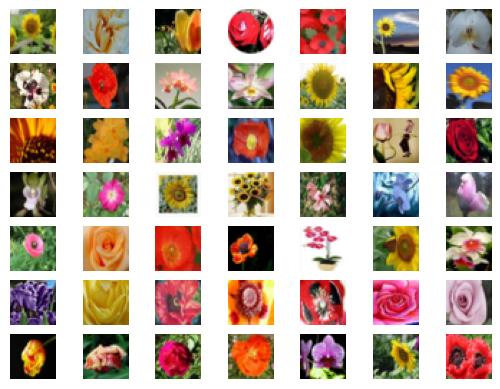

In [1]:
# example of loading and plotting the cifar100 flowers subset
from keras.datasets.cifar100 import load_data
from matplotlib import pyplot
import numpy as np

# load the images into memory (coarse labels: 2 = flowers)
(trainX, trainy), (testX, testy) = load_data(label_mode='coarse')

# keep only the flowers class, and only a small part of it
FLOWERS = 2
N_IMAGES = 1000   # change this to use more/fewer images
trainX = trainX[trainy.flatten() == FLOWERS][:N_IMAGES]

# plot images from the dataset
for i in range(49):
    # define subplot
    pyplot.subplot(7, 7, 1 + i)
    # turn off axis
    pyplot.axis('off')
    # plot raw pixel data
    pyplot.imshow(trainX[i])

pyplot.show()

## 2. Checking the Dataset Dimensions

Display the shape of the selected training images to verify the number of images, image height, image width, and RGB color channels.

In [2]:
print(trainX.shape)

(1000, 32, 32, 3)


## 3. Building the Discriminator Model

Define a Convolutional Neural Network (CNN) discriminator using convolutional layers and LeakyReLU activation. The discriminator learns to distinguish real flower images from images generated by the GAN.

In [3]:
# example of defining the discriminator model
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense
from keras.layers import Conv2D
from keras.layers import Flatten
from keras.layers import Dropout
from keras.layers import LeakyReLU
from keras.utils import plot_model
import numpy as np

# define the standalone discriminator model
def define_discriminator(in_shape=(32,32,3)):
    model = Sequential()

    # normal
    model.add(Conv2D(64, (3,3), padding='same', input_shape=in_shape))
    model.add(LeakyReLU(negative_slope=0.2))

    # downsample
    model.add(Conv2D(128, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))

    # downsample
    model.add(Conv2D(128, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))

    # downsample
    model.add(Conv2D(256, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))

    # classifier
    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))

    # compile model
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

## 4. Discriminator Model Summary

Display the discriminator architecture, including its layers and parameter counts. Generate a visual representation of the model to understand its structure and input/output dimensions.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 522,497 (1.99 MB)

 Trainable params: 522,497 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

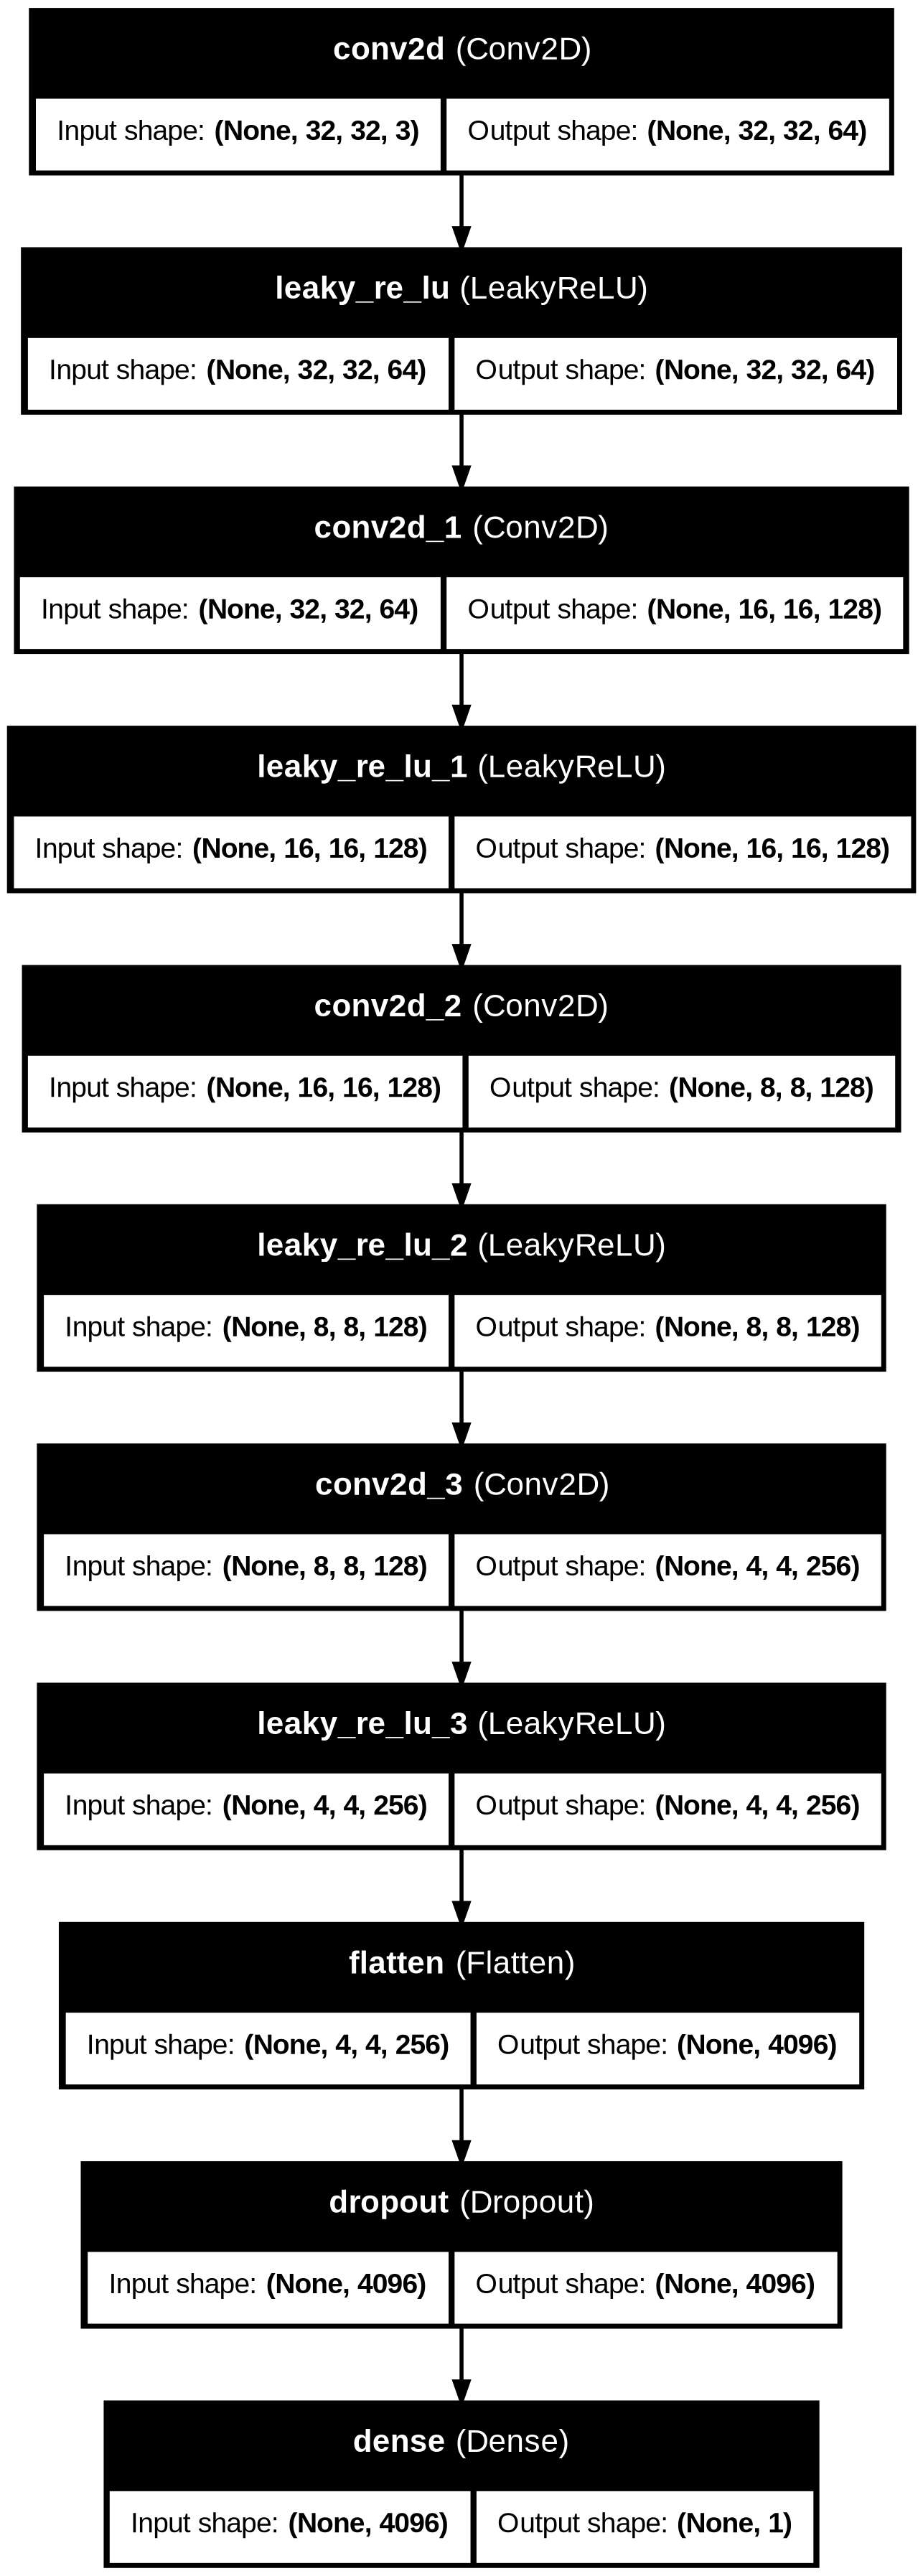

In [4]:
# define model
model = define_discriminator()

# summarize the model
model.summary()

# plot the model
plot_model(model, to_file='discriminator_plot.png', show_shapes=True, show_layer_names=True)

## 5. Loading and Preprocessing Real Images

Load the CIFAR-100 dataset, select the Flowers superclass, and retain the first 1,000 images. Convert pixel values to floating-point numbers and normalize them from the range [0, 255] to [-1, 1] for GAN training.

In [5]:
# Function to load the dataset and scale it
# load and prepare the cifar100 flowers training images
def load_real_samples():
    # load cifar100 dataset with coarse labels
    (trainX, trainy), (testX, testy) = load_data(label_mode='coarse')
    # keep only the flowers class (coarse label 2), and only the first 1000 images
    X = trainX[trainy.flatten() == 2][:1000]
    # convert from unsigned ints to floats
    X = X.astype('float32')
    # scale from [0, 255] to [-1, 1]
    X = (X - 127.5) / 127.5
    return X

## 6. Verifying the Preprocessed Dataset

Load the preprocessed flower images and print the dataset shape, minimum pixel value, and maximum pixel value to verify that normalization has been applied correctly.

In [6]:
X = load_real_samples()
print(X.shape, X.min(), X.max())

(1000, 32, 32, 3) -1.0 1.0


## 7. Selecting Real Training Samples

Randomly select images from the preprocessed dataset and assign the label 1 to each image. These real samples are used to train the discriminator to recognize genuine flower images.

In [7]:
# select real samples   128 samples it will train in batches 64- real, 64-fake   y is label as 1 because it is real
def generate_real_samples(dataset, n_samples):
    # choose random instances
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    # retrieve selected images
    X = dataset[ix]
    # generate 'real' class labels (1)
    y = np.ones((n_samples, 1))
    return X, y

## 8. Generating Random Fake Images for Initial Discriminator Training

Generate random RGB images with dimensions 32 × 32 × 3 and normalize their values to [-1, 1]. Assign label 0 to these images. This function is used for preliminary discriminator training and is later redefined to generate images using the trained generator.

In [8]:
# generate n fake samples with class labels (random noise images, used only to test the discriminator)
def generate_fake_samples(n_samples):
    # generate uniform random numbers in [0,1]
    X = np.random.rand(32 * 32 * 3 * n_samples)
    # update to have the range [-1, 1]
    X = -1 + X * 2
    # reshape into a batch of color images
    X = X.reshape((n_samples, 32, 32, 3))
    # generate 'fake' class labels (0)
    y = np.zeros((n_samples, 1))
    return X, y

## 9. Preliminary Discriminator Training

Train the discriminator separately using batches of real flower images and randomly generated fake images. Calculate the discriminator loss and accuracy for both groups to examine its initial classification performance.

In [9]:
# train the discriminator model temporarily
def train_discriminator(model, dataset, n_iter=20, n_batch=128):
    half_batch = int(n_batch / 2)
    # manually enumerate epochs
    for i in range(n_iter):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # update discriminator on real samples
        _, real_acc = model.train_on_batch(X_real, y_real)
        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples(half_batch)
        # update discriminator on fake samples
        _, fake_acc = model.train_on_batch(X_fake, y_fake)
        # summarize performance
        print('>%d real=%.0f%% fake=%.0f%%' % (i+1, real_acc*100, fake_acc*100))

# Example Training
model = define_discriminator()
dataset = load_real_samples()
train_discriminator(model, dataset)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


>1 real=77% fake=38%
>2 real=59% fake=44%
>3 real=55% fake=47%
>4 real=54% fake=49%
>5 real=55% fake=55%
>6 real=59% fake=61%
>7 real=64% fake=67%
>8 real=68% fake=70%
>9 real=71% fake=73%
>10 real=74% fake=75%
>11 real=76% fake=77%
>12 real=78% fake=79%
>13 real=79% fake=80%
>14 real=80% fake=81%
>15 real=82% fake=82%
>16 real=83% fake=83%
>17 real=84% fake=84%
>18 real=85% fake=85%
>19 real=85% fake=86%
>20 real=86% fake=86%


## 10. Building the Generator Model

Define the generator using a dense layer, reshaping, and transposed convolutional layers. It transforms a 100-dimensional latent vector of random noise into a 32 × 32 RGB image. The output uses the tanh activation function to produce pixel values in the range [-1, 1].


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4096)           │       413,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 3)      │         3,459 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,466,115 (5.59 MB)

 Trainable params: 1,466,115 (5.59 MB)

 Non-trainable params: 0 (0.00 B)

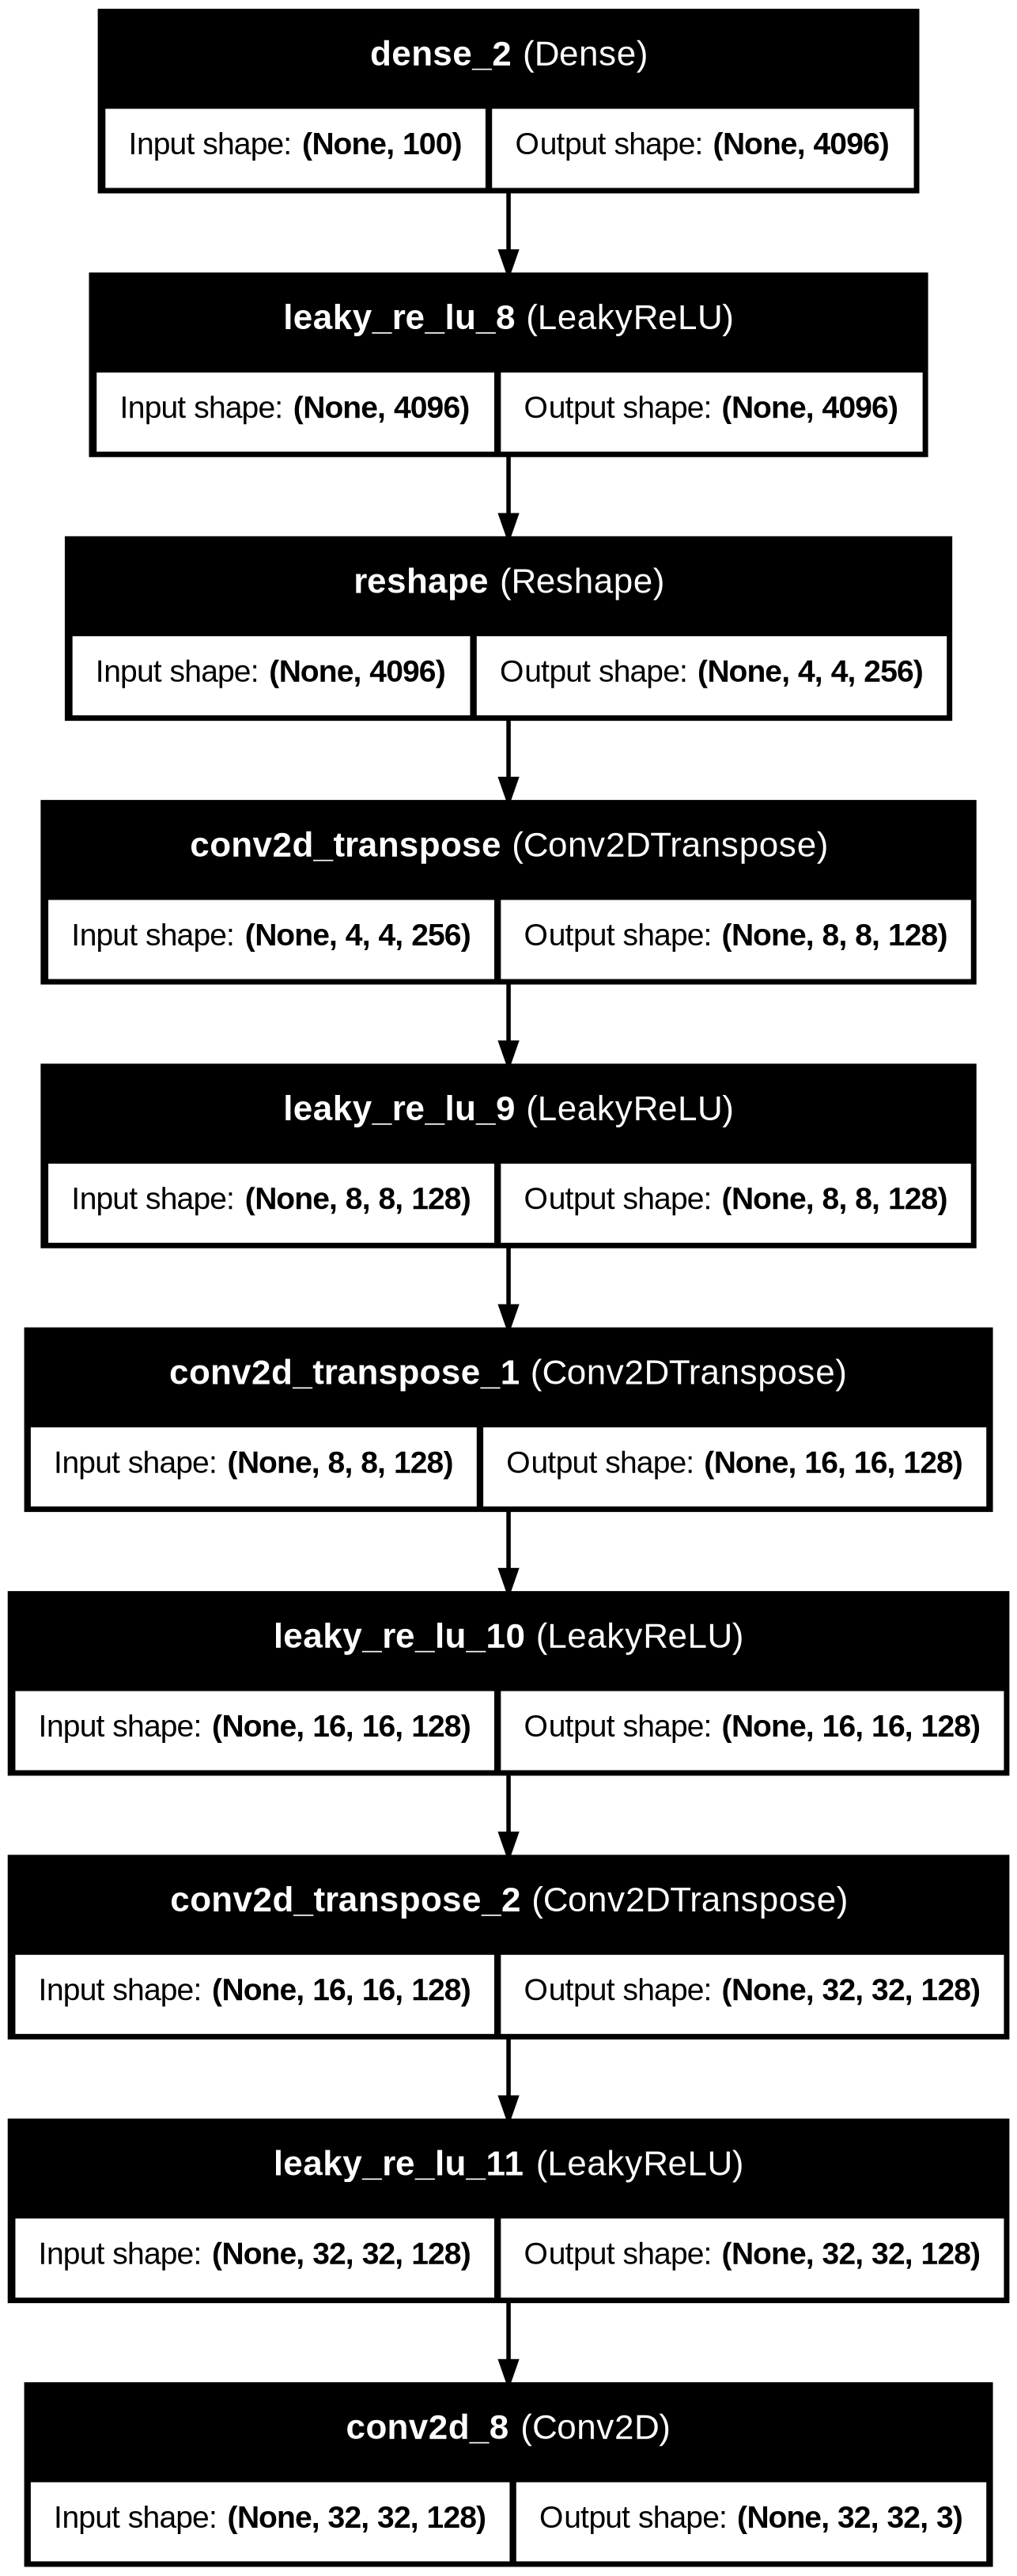

In [10]:
from keras.models import Sequential
from keras.layers import Dense, Reshape, Conv2D, Conv2DTranspose, LeakyReLU
from keras.utils import plot_model

# define the standalone generator model
def define_generator(latent_dim):
    model = Sequential()
    # foundation for 4x4 image
    n_nodes = 256 * 4 * 4
    model.add(Dense(n_nodes, input_dim=latent_dim))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Reshape((4, 4, 256)))

    # upsample to 8x8
    model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))

    # upsample to 16x16
    model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))

    # upsample to 32x32
    model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
    model.add(LeakyReLU(negative_slope=0.2))

    # output layer (3 channels for RGB)
    model.add(Conv2D(3, (3,3), activation='tanh', padding='same'))
    return model

# define size of latent space & model summary
latent_dim = 100
model = define_generator(latent_dim)
model.summary()
plot_model(model, to_file='generator_plot.png', show_shapes=True, show_layer_names=True)

## 11. Generating Latent Vectors and Synthetic Images

Generate random latent vectors from a normal distribution and pass them through the generator to produce synthetic flower images. Assign label 0 to the generated images for discriminator training.

In [11]:
# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
    # generate points in the latent space
    x_input = np.random.randn(latent_dim * n_samples)
    # reshape into a batch of inputs for the network
    x_input = x_input.reshape(n_samples, latent_dim)
    return x_input

# use the generator to generate n fake examples, with class labels
# (this redefines generate_fake_samples, now using the generator instead of noise)
def generate_fake_samples(g_model, latent_dim, n_samples):
    # generate points in latent space
    x_input = generate_latent_points(latent_dim, n_samples)
    # predict outputs
    X = g_model.predict(x_input, verbose=0)
    # create 'fake' class labels (0)
    y = np.zeros((n_samples, 1))
    return X, y

## 12. Visualizing Images Generated by the Untrained Generator

Create the generator using a latent dimension of 100, generate 49 synthetic images, and rescale their pixel values from [-1, 1] to [0, 1] for display. Visualize the results to observe the generator's initial output before adversarial training.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


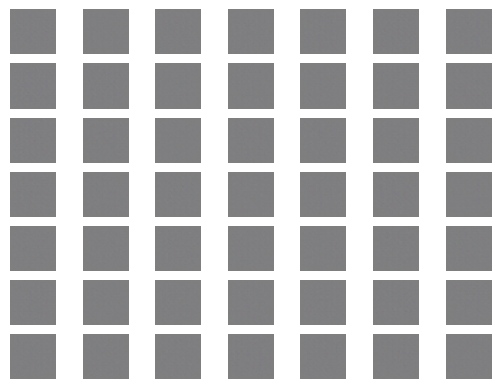

In [12]:
# size of the latent space
latent_dim = 100

# define the generator model
model = define_generator(latent_dim)

# generate samples
n_samples = 49
X, _ = generate_fake_samples(model, latent_dim, n_samples)

# scale pixel values from [-1,1] to [0,1]
X = (X + 1) / 2.0

# plot the generated samples
for i in range(n_samples):
    # define subplot
    pyplot.subplot(7, 7, 1 + i)
    # turn off axis labels
    pyplot.axis('off')
    # plot single image
    pyplot.imshow(X[i])

# show the figure
pyplot.show()

## 13. Building the Combined GAN Model

Combine the generator and discriminator into a single GAN model. Freeze the discriminator's weights while training the combined model so that the generator learns to produce images that the discriminator classifies as real. Compile the model using binary cross-entropy loss and the Adam optimizer.

In [13]:
# define the combined generator and discriminator model, for updating the generator
def define_gan(g_model, d_model):
    # make weights in the discriminator not trainable
    d_model.trainable = False
    # connect them
    model = Sequential()
    # add generator
    model.add(g_model)
    # add the discriminator
    model.add(d_model)
    # compile model
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)
    return model

## 14. Visualizing and Evaluating GAN Performance

Define functions to display and save generated images at different training stages. Evaluate the discriminator on real and generated samples, compare classification accuracy, and save the generator model to monitor training progress.

In [14]:
# create and save a plot of generated images
def save_plot(examples, epoch, n=7):
    # scale from [-1,1] to [0,1]
    examples = (examples + 1) / 2.0
    # plot images
    for i in range(n * n):
        # define subplot
        pyplot.subplot(n, n, 1 + i)
        # turn off axis
        pyplot.axis('off')
        # plot raw pixel data
        pyplot.imshow(examples[i])
    # save plot to file
    filename = 'generated_plot_e%03d.png' % (epoch+1)
    pyplot.savefig(filename)
    pyplot.show()
    pyplot.close()

# evaluate the discriminator, plot generated images, save generator model
def summarize_performance(epoch, g_model, d_model, dataset, latent_dim, n_samples=150):
    # prepare real samples
    X_real, y_real = generate_real_samples(dataset, n_samples)
    # evaluate discriminator on real examples
    _, acc_real = d_model.evaluate(X_real, y_real, verbose=0)
    # prepare fake examples
    x_fake, y_fake = generate_fake_samples(g_model, latent_dim, n_samples)
    # evaluate discriminator on fake examples
    _, acc_fake = d_model.evaluate(x_fake, y_fake, verbose=0)
    # summarize discriminator performance
    print('>Accuracy real: %.0f%%, fake: %.0f%%' % (acc_real*100, acc_fake*100))
    # save plot
    save_plot(x_fake, epoch)
    # save the generator model file
    filename = 'generator_model_%03d.keras' % (epoch+1)
    g_model.save(filename)

## 15. Training the Generator and Discriminator

Train the GAN adversarially for 100 epochs using a batch size of 64. Update the discriminator using real and generated images, then train the generator through the combined GAN model. Periodically evaluate performance, save generated image grids, and save the trained generator model.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


>1, 15/15, d1=0.708, d2=0.713 g=0.650
>2, 15/15, d1=0.766, d2=0.770 g=0.563
>3, 15/15, d1=0.807, d2=0.811 g=0.512
>4, 15/15, d1=0.839, d2=0.842 g=0.476
>5, 15/15, d1=0.862, d2=0.865 g=0.450
>6, 15/15, d1=0.880, d2=0.882 g=0.431
>7, 15/15, d1=0.895, d2=0.897 g=0.416
>8, 15/15, d1=0.907, d2=0.908 g=0.404
>9, 15/15, d1=0.917, d2=0.918 g=0.394
>10, 15/15, d1=0.925, d2=0.927 g=0.386
>Accuracy real: 81%, fake: 0%


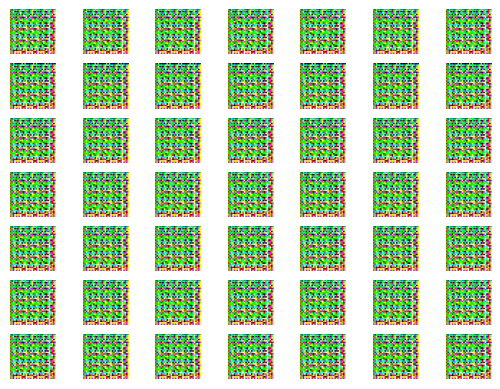

>11, 15/15, d1=1.048, d2=1.057 g=0.379
>12, 15/15, d1=1.032, d2=1.037 g=0.372
>13, 15/15, d1=1.029, d2=1.033 g=0.367
>14, 15/15, d1=1.028, d2=1.031 g=0.362
>15, 15/15, d1=1.028, d2=1.030 g=0.357
>16, 15/15, d1=1.029, d2=1.031 g=0.353
>17, 15/15, d1=1.029, d2=1.031 g=0.349
>18, 15/15, d1=1.031, d2=1.032 g=0.346
>19, 15/15, d1=1.032, d2=1.033 g=0.342
>20, 15/15, d1=1.033, d2=1.035 g=0.339
>Accuracy real: 80%, fake: 0%


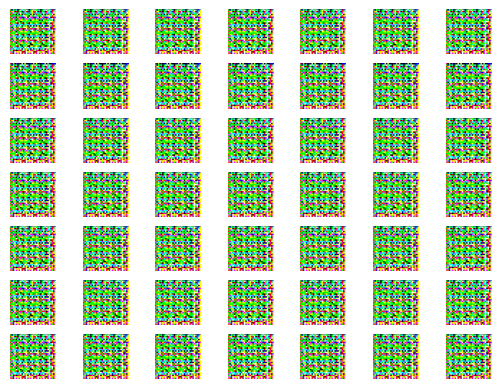

>21, 15/15, d1=1.091, d2=1.101 g=0.336
>22, 15/15, d1=1.074, d2=1.079 g=0.334
>23, 15/15, d1=1.069, d2=1.073 g=0.331
>24, 15/15, d1=1.067, d2=1.070 g=0.329
>25, 15/15, d1=1.066, d2=1.068 g=0.326
>26, 15/15, d1=1.065, d2=1.067 g=0.324
>27, 15/15, d1=1.065, d2=1.067 g=0.322
>28, 15/15, d1=1.065, d2=1.067 g=0.320
>29, 15/15, d1=1.065, d2=1.067 g=0.319
>30, 15/15, d1=1.065, d2=1.067 g=0.317
>Accuracy real: 75%, fake: 0%


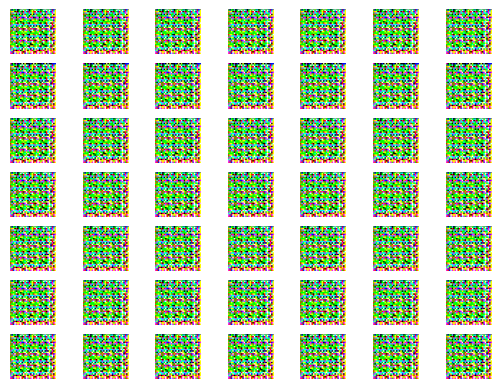

>31, 15/15, d1=1.111, d2=1.121 g=0.315
>32, 15/15, d1=1.091, d2=1.097 g=0.314
>33, 15/15, d1=1.084, d2=1.088 g=0.312
>34, 15/15, d1=1.080, d2=1.084 g=0.311
>35, 15/15, d1=1.079, d2=1.082 g=0.310
>36, 15/15, d1=1.078, d2=1.080 g=0.308
>37, 15/15, d1=1.077, d2=1.079 g=0.307
>38, 15/15, d1=1.077, d2=1.078 g=0.306
>39, 15/15, d1=1.076, d2=1.078 g=0.305
>40, 15/15, d1=1.076, d2=1.077 g=0.304
>Accuracy real: 73%, fake: 0%


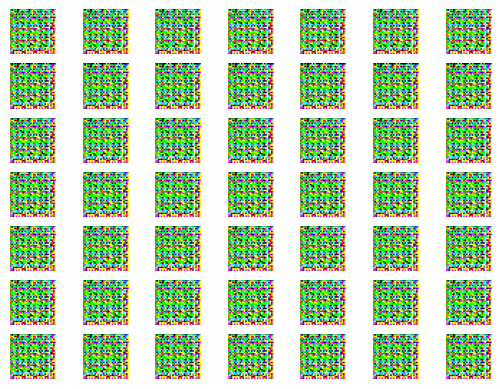

>41, 15/15, d1=1.119, d2=1.129 g=0.303
>42, 15/15, d1=1.097, d2=1.103 g=0.302
>43, 15/15, d1=1.090, d2=1.094 g=0.301
>44, 15/15, d1=1.087, d2=1.090 g=0.300
>45, 15/15, d1=1.085, d2=1.087 g=0.299
>46, 15/15, d1=1.083, d2=1.085 g=0.299
>47, 15/15, d1=1.082, d2=1.084 g=0.298
>48, 15/15, d1=1.082, d2=1.083 g=0.297
>49, 15/15, d1=1.081, d2=1.083 g=0.296
>50, 15/15, d1=1.081, d2=1.082 g=0.296
>Accuracy real: 87%, fake: 0%


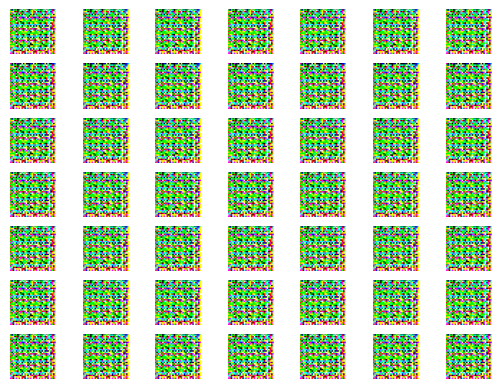

>51, 15/15, d1=1.121, d2=1.131 g=0.295
>52, 15/15, d1=1.101, d2=1.107 g=0.294
>53, 15/15, d1=1.094, d2=1.098 g=0.294
>54, 15/15, d1=1.090, d2=1.093 g=0.293
>55, 15/15, d1=1.088, d2=1.090 g=0.292
>56, 15/15, d1=1.086, d2=1.088 g=0.292
>57, 15/15, d1=1.085, d2=1.087 g=0.291
>58, 15/15, d1=1.085, d2=1.087 g=0.291
>59, 15/15, d1=1.085, d2=1.086 g=0.290
>60, 15/15, d1=1.084, d2=1.086 g=0.290
>Accuracy real: 73%, fake: 0%


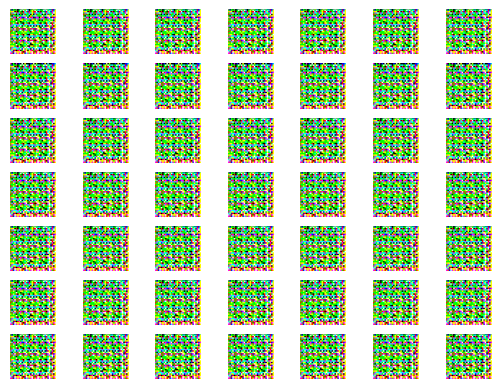

>61, 15/15, d1=1.124, d2=1.134 g=0.289
>62, 15/15, d1=1.103, d2=1.108 g=0.289
>63, 15/15, d1=1.096, d2=1.100 g=0.288
>64, 15/15, d1=1.093, d2=1.096 g=0.288
>65, 15/15, d1=1.090, d2=1.093 g=0.287
>66, 15/15, d1=1.089, d2=1.091 g=0.287
>67, 15/15, d1=1.088, d2=1.089 g=0.287
>68, 15/15, d1=1.087, d2=1.089 g=0.286
>69, 15/15, d1=1.087, d2=1.088 g=0.286
>70, 15/15, d1=1.086, d2=1.088 g=0.285
>Accuracy real: 75%, fake: 0%


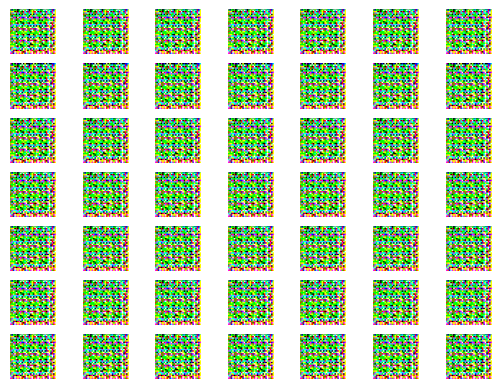

>71, 15/15, d1=1.123, d2=1.132 g=0.285
>72, 15/15, d1=1.103, d2=1.109 g=0.285
>73, 15/15, d1=1.097, d2=1.101 g=0.284
>74, 15/15, d1=1.094, d2=1.097 g=0.284
>75, 15/15, d1=1.091, d2=1.094 g=0.284
>76, 15/15, d1=1.090, d2=1.092 g=0.283
>77, 15/15, d1=1.089, d2=1.091 g=0.283
>78, 15/15, d1=1.088, d2=1.089 g=0.283
>79, 15/15, d1=1.087, d2=1.089 g=0.282
>80, 15/15, d1=1.087, d2=1.088 g=0.282
>Accuracy real: 89%, fake: 0%


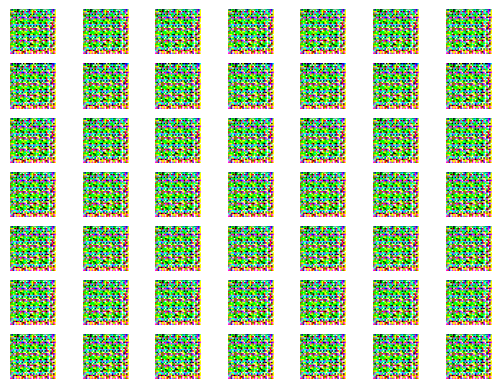

>81, 15/15, d1=1.127, d2=1.137 g=0.282
>82, 15/15, d1=1.106, d2=1.112 g=0.282
>83, 15/15, d1=1.099, d2=1.103 g=0.281
>84, 15/15, d1=1.096, d2=1.099 g=0.281
>85, 15/15, d1=1.094, d2=1.097 g=0.281
>86, 15/15, d1=1.092, d2=1.095 g=0.280
>87, 15/15, d1=1.091, d2=1.093 g=0.280
>88, 15/15, d1=1.091, d2=1.092 g=0.280
>89, 15/15, d1=1.090, d2=1.091 g=0.280
>90, 15/15, d1=1.089, d2=1.090 g=0.279
>Accuracy real: 75%, fake: 0%


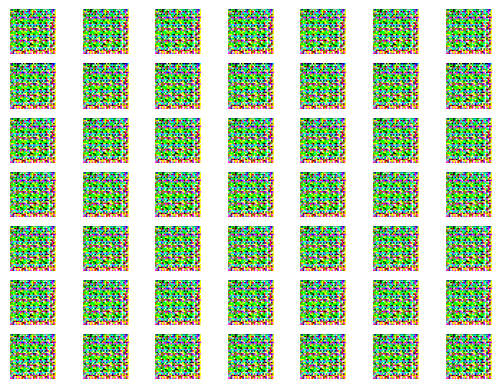

>91, 15/15, d1=1.126, d2=1.136 g=0.279
>92, 15/15, d1=1.107, d2=1.113 g=0.279
>93, 15/15, d1=1.100, d2=1.104 g=0.279
>94, 15/15, d1=1.098, d2=1.101 g=0.278
>95, 15/15, d1=1.096, d2=1.098 g=0.278
>96, 15/15, d1=1.095, d2=1.097 g=0.278
>97, 15/15, d1=1.094, d2=1.096 g=0.278
>98, 15/15, d1=1.094, d2=1.095 g=0.278
>99, 15/15, d1=1.093, d2=1.095 g=0.277
>100, 15/15, d1=1.093, d2=1.094 g=0.277
>Accuracy real: 83%, fake: 0%


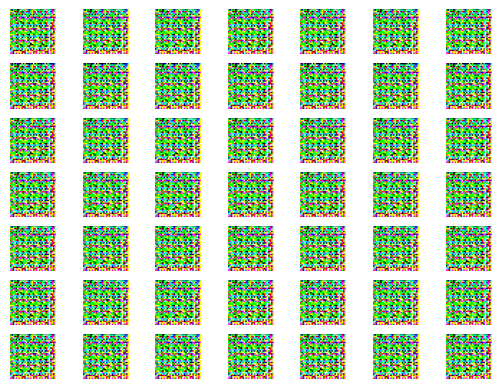

In [15]:
from numpy import ones

# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=100, n_batch=64):
    bat_per_epo = int(dataset.shape[0] / n_batch)
    half_batch = int(n_batch / 2)
    # manually enumerate epochs
    for i in range(n_epochs):
        # enumerate batches over the training set
        for j in range(bat_per_epo):
            # get randomly selected 'real' samples
            X_real, y_real = generate_real_samples(dataset, half_batch)
            # update discriminator model weights
            d_loss1, _ = d_model.train_on_batch(X_real, y_real)
            # generate 'fake' examples
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
            # update discriminator model weights
            d_loss2, _ = d_model.train_on_batch(X_fake, y_fake)
            # prepare points in latent space as input for the generator
            X_gan = generate_latent_points(latent_dim, n_batch)
            # create inverted labels for the fake samples
            y_gan = ones((n_batch, 1))
            # update the generator via the discriminator's error
            g_loss = gan_model.train_on_batch(X_gan, y_gan)
            # summarize loss (every 100 batches to keep the output short)
            if (j+1) % 100 == 0 or j == bat_per_epo - 1:
                print('>%d, %d/%d, d1=%.3f, d2=%.3f g=%.3f' %
                      (i+1, j+1, bat_per_epo, d_loss1, d_loss2, g_loss))
        # evaluate the model performance, sometimes
        if (i+1) % 10 == 0:
            summarize_performance(i, g_model, d_model, dataset, latent_dim)

# size of the latent space
latent_dim = 100
# create the discriminator
d_model = define_discriminator()
# create the generator
g_model = define_generator(latent_dim)
# create the gan
gan_model = define_gan(g_model, d_model)
# load image data
dataset = load_real_samples()
# execute training
train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=100, n_batch=64)

## 16. Generating Final Flower Images

Generate 49 latent vectors and pass them through the trained generator to produce synthetic 32 × 32 RGB images. Display and save the final generated images to visually assess how well the GAN has learned flower-like patterns.

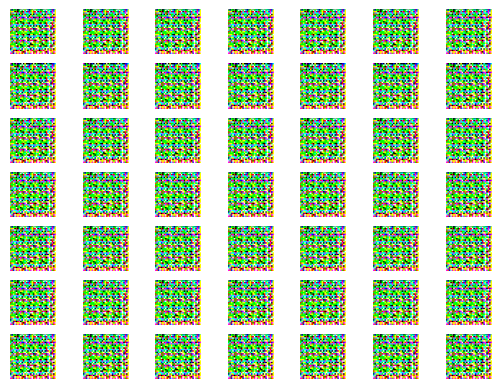

In [16]:
# generate and view final images using the trained generator
latent_points = generate_latent_points(latent_dim, 49)
X = g_model.predict(latent_points, verbose=0)
save_plot(X, 999)